In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
from pathlib import Path

if 'google.colab' in sys.modules:
    repo_name = "study-mikanos"
    repo_url = "https://github.com/miyayudai/study-mikanos.git"
    if not Path(repo_name).exists():
        !git clone $repo_url
    %cd $repo_name
    if not Path("build/bin/ch05_os_chapter5_exercises").exists():
        !cmake -B build -S . -DCMAKE_BUILD_TYPE=Release
        !cmake --build build --target ch05_os_chapter5_exercises -j$(nproc)
    sys.path.insert(0, str(Path.cwd()))
    print("Colab setup complete.")
else:
    print(f"Local environment detected: {Path.cwd()}")


Local environment detected: /home/student/Documents/GitHub/study-mikanos/5


# 第5章 文字表示とコンソールクラス — 総合演習問題 (*Chapter 5 Comprehensive Exercises*)

名著『**ゼロからのOS自作入門**』（内田公太 著）第5章「文字表示とコンソールクラス」で学んだ、
1. **5.1 文字を書いてみる (`osbook_day05a`)**: 8x16 ビットマップフォントのビット展開数理、MSBからLSBへのピクセルマッピング、C++参照（Reference）とポインタの言語仕様比較
2. **5.2 分割コンパイル (`osbook_day05b`)**: ヘッダ（宣言）とソース（定義）の分離、インクルードガード（`#pragma once`）と単一定義規則（ODR: One Definition Rule）、リンカシンボル解決と再配置
3. **5.3 フォントを増やそう (`osbook_day05c`)**: GNU objcopy による任意バイナリ（`hankaku.bin`）のELFオブジェクト化、3大リンカシンボル（`_binary_hankaku_bin_start`, `end`, `size`）とポインタ算術
4. **5.4 文字列描画とsprintf() (`osbook_day05d`)**: Newlib 標準Cライブラリ（`libc.a`）の静的リンク、`sbrk` メモリ確保スタブ、System V AMD64 ABI における可変長引数（`va_list`）の4大レジスタ退避構造
5. **5.5 コンソールクラス (`osbook_day05e`)**: 25行×80列の2次元文字バッファ、改行文字（`\n`）の処理、最下行到達時の行シフトスクロールと全画面再描画
6. **5.6 printk() (`osbook_day05f`)**: `va_list` / `va_start` / `vsnprintf` によるカーネル書式付き出力、固定長バッファ切り詰め安全性（Truncation Safety）、配置 `new`（Placement new）によるグローバル `Console` の初期化

の全理論・数理・実装・ABI仕様を完全網羅する総合演習問題です。

本ノートブックでは、自作OSの低レイヤプログラミングで必須となる数理の導出、理論検証、C++20 スタンドアロンバイナリによる単体検証、および10問の自己採点テストとレーダーチャート可視化を行います。


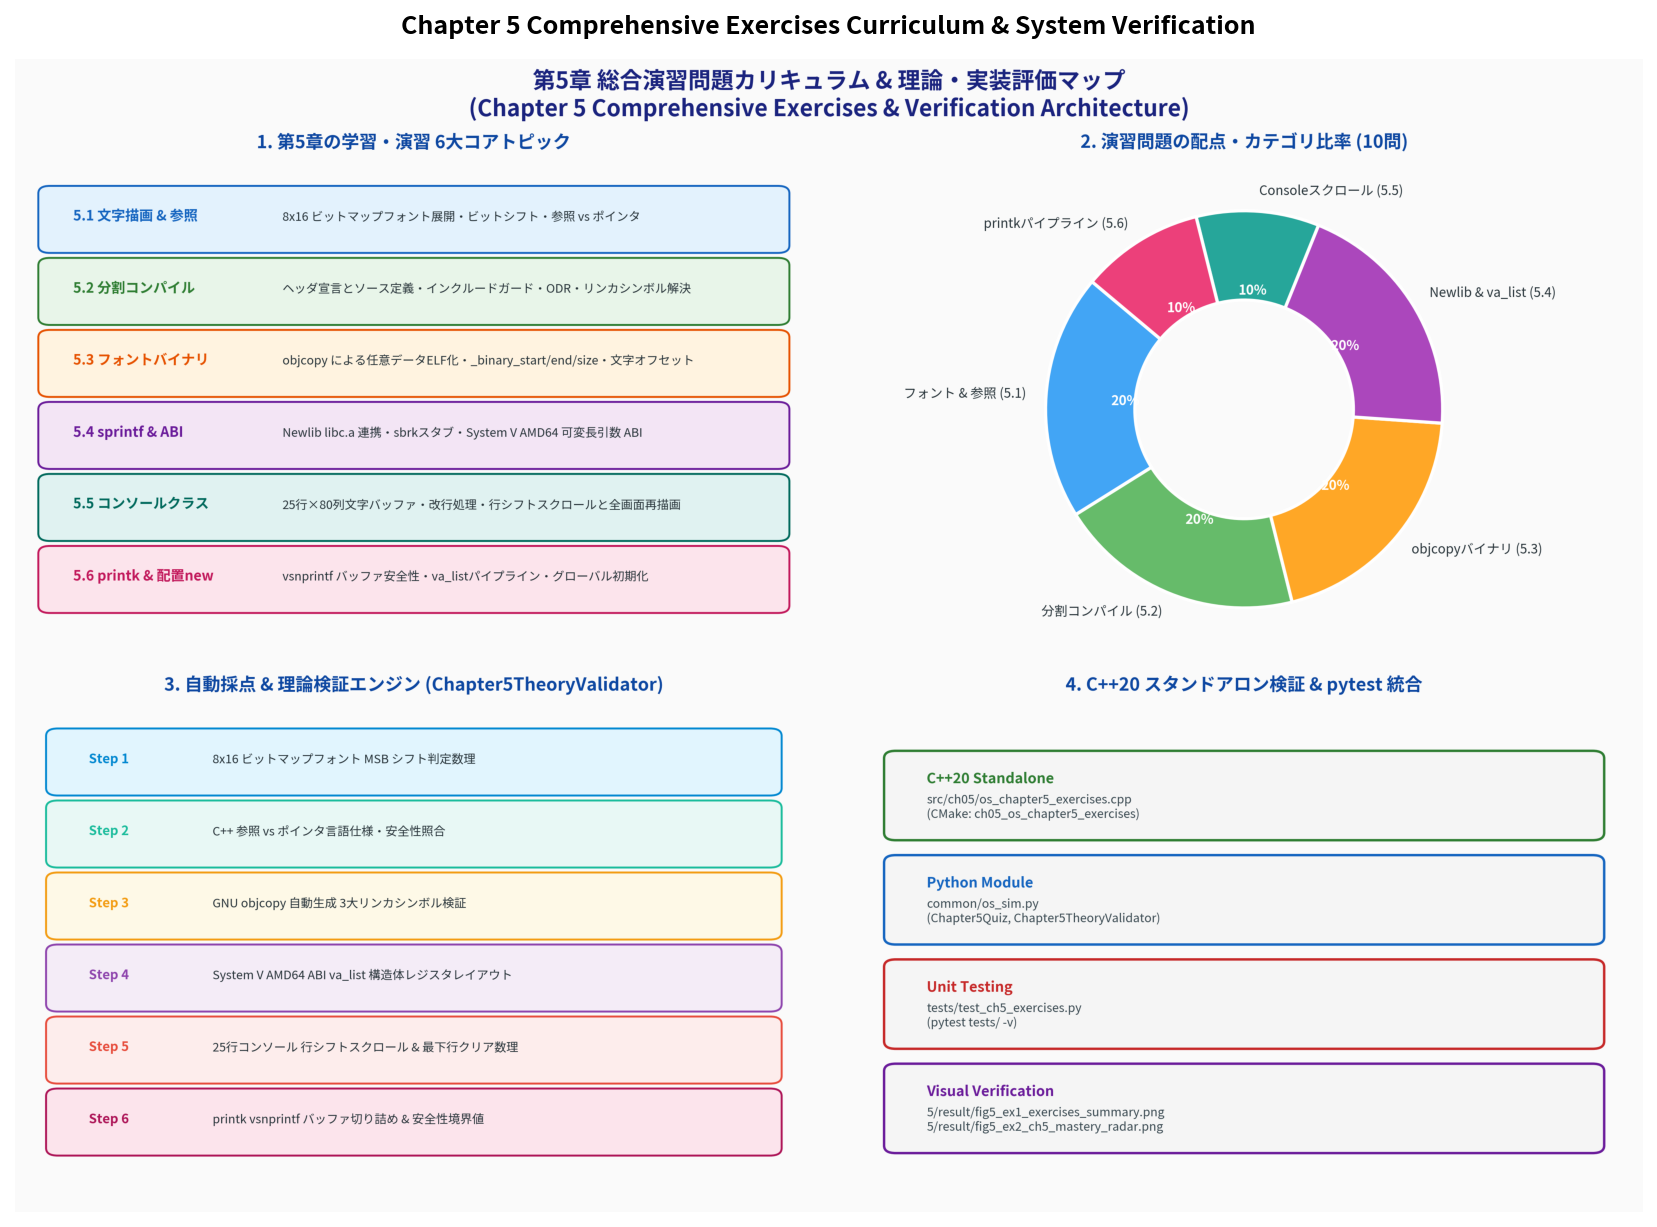

In [2]:
from pathlib import Path
import matplotlib.pyplot as plt
from PIL import Image

from common.os_sim import (
    Chapter5Quiz,
    Chapter5TheoryValidator,
    plot_chapter5_exercises_summary,
    plot_chapter5_mastery_radar,
)

# 第5章総合演習カリキュラム・アーキテクチャ概要図の生成と表示
summary_fig_path = Path("result/fig5_ex1_exercises_summary.png")
plot_chapter5_exercises_summary(summary_fig_path)

img_summary = Image.open(summary_fig_path)
plt.figure(figsize=(14, 10))
plt.imshow(img_summary)
plt.axis("off")
plt.title("Chapter 5 Comprehensive Exercises Curriculum & System Verification", fontsize=12, fontweight="bold", pad=12)
plt.show()


---

## 📝 演習 1: 8x16 ビットマップフォントのビット展開数理と文字描画アルゴリズム

### 1. 理論背景と導出
8x16 ドットの半角フォントデータ（例: `hankaku.txt` や `kFontA`）は、高さ 16 ピクセル、幅 8 ピクセルのグリフを行ごとに 1 バイト（8 ビット）として表します。

1文字のデータサイズ：
$$
	ext{Font Glyph Size} = 16 	ext{ 行} 	imes 1 	ext{ バイト/行} = 16 	ext{ バイト}
$$

各行 $dy \in [0, 15]$ のバイトデータ $	ext{font}[dy]$ において、列 $dx \in [0, 7]$ のピクセルが点灯しているかの判定式：
- 最も左側のピクセル（$dx = 0$）は **最上位ビット（MSB: Bit 7）** に対応します。
- したがって、左へ $dx$ ビットシフトして $0	ext{x}80$（Bit 7）をマスクするか、右へ $(7 - dx)$ ビットシフトして最下位ビット（LSB: Bit 0）を検査します：

$$
	ext{IsLit}(dy, dx) = \left( (	ext{font}[dy] \ll dx) \ \& \ 0	ext{x}80 ight) 
eq 0
\quad \Longleftrightarrow \quad
\left( (	ext{font}[dy] \gg (7 - dx)) \ \& \ 1 ight) 
eq 0
$$

VRAM 座標 $(x + dx, y + dy)$ への描画オフセット計算式（1ピクセル=4バイト、走査線幅=pixels_per_scan_line）：
$$
	ext{ByteOffset}(dx, dy) = 4 	imes \left( (y + dy) 	imes 	ext{ppsl} + (x + dx) ight)
$$


In [3]:
# 演習 1: 8x16 ビットマップフォント展開数理の自動検証
mock_font_byte = 0b10010000  # dy行目のバイト (MSB=1, Bit 4=1, その他=0)

# dx=0 (左端): 点灯 (True)
ok0, msg0 = Chapter5TheoryValidator.validate_font_bit_expansion({
    "font_byte": mock_font_byte,
    "dx": 0,
    "is_lit": bool((mock_font_byte << 0) & 0x80),
})
assert ok0, msg0

# dx=1: 消灯 (False)
ok1, msg1 = Chapter5TheoryValidator.validate_font_bit_expansion({
    "font_byte": mock_font_byte,
    "dx": 1,
    "is_lit": bool((mock_font_byte << 1) & 0x80),
})
assert ok1, msg1

# dx=3: 点灯 (True) -> (0b10010000 << 3) & 0x80 == 0x80
ok3, msg3 = Chapter5TheoryValidator.validate_font_bit_expansion({
    "font_byte": mock_font_byte,
    "dx": 3,
    "is_lit": bool((mock_font_byte << 3) & 0x80),
})
assert ok3, msg3

print("[OK] 演習 1: 8x16 ビットマップフォントの MSB ビット展開アルゴリズムを完全検証しました。")


[OK] 演習 1: 8x16 ビットマップフォントの MSB ビット展開アルゴリズムを完全検証しました。


---

## 📝 演習 2: C++ 参照 vs ポインタの言語仕様・安全性と分割コンパイル

### 1. 参照（`T&`）とポインタ（`T*`）の本質的な差異
自作OSカーネルの設計において、引数引き渡しやリソース管理に参照とポインタを正しく使い分けることは安全性の根幹を成します：

| 比較項目 | 参照 (`T&`) | ポインタ (`T*`) | OS開発での採用基準 |
|:---|:---|:---|:---|
| **Null可能性** | **不可 (nullptr 不可)** | 可能 (`nullptr` / `NULL`) | 確実に存在するインスタンス（`PixelWriter&` 等）は参照で渡す |
| **初期化要件** | **宣言時必須** | 任意（未初期化は未定義動作） | 参照を用いることで未初期化ポインタ参照（バグ）を防止 |
| **再束縛 (Rebind)** | **不可**（値の代入になる） | 可能（別のアドレスを指し直せる） | オブジェクトの所有・エイリアス固定には参照 |
| **アクセス構文** | ドット演算子 `obj.Member()` | アロー演算子 `ptr->Member()` | 構文が簡潔になり可読性が向上 |

### 2. 分割コンパイルと単一定義規則 (ODR: One Definition Rule)
- **ヘッダファイル (`.hpp`)**: クラス定義・関数宣言・外部変数宣言（`extern`）を記述。
- **インクルードガード (`#pragma once`)**: 同一翻訳単位（Translation Unit）内での多重インクルードによるクラス多重定義（ODR違反）を防止。
- **ソースファイル (`.cpp`)**: 関数の実体定義を記述。コンパイラが `.o` オブジェクトファイルを出力し、リンカが未解決外部シンボルをアドレス解決（Relocation）します。


In [4]:
# 演習 2: C++ 参照 vs ポインタ言語仕様の自動検証
reference_rules = {
    "ref_can_be_null": False,       # 参照はnullptr不可
    "ref_can_rebind": False,        # 一度束縛した対象は変更不可
    "ref_access_operator": ".",     # ドット演算子でアクセス
    "ptr_access_operator": "->",    # ポインタはアロー演算子
}

ok_ref, msg_ref = Chapter5TheoryValidator.validate_reference_vs_pointer(reference_rules)
assert ok_ref, msg_ref

print(f"[OK] 演習 2: {msg_ref}")


[OK] 演習 2: 正解！C++参照とポインタの構文・セマンティクス・安全性の差異を正確に識別しました。


---

## 📝 演習 3: GNU objcopy による任意バイナリの ELF 化とリンカシンボル

### 1. `objcopy` によるデータバイナリのオブジェクト化
画像やフォント（`hankaku.bin`）などの静的バイナリリソースを C++ ソースから参照可能にするため、GNU `objcopy` を用いて ELF64 オブジェクトファイルへ変換します：

```bash
objcopy -I binary -O elf64-x86-64 -B i386:x86-64 hankaku.bin hankaku.o
```

このコマンドにより、リンカは以下の3つの大域シンボルを自動的にエクスポートします：
1. `_binary_hankaku_bin_start`: バイナリデータの先頭アドレス
2. `_binary_hankaku_bin_end`: バイナリデータの終端直後アドレス
3. `_binary_hankaku_bin_size`: バイナリデータのバイトサイズ（シンボル値として保持）

### 2. 文字フォントアドレス計算式
文字コード $c \in [0, 255]$ に対応する 16 バイトのフォントデータのアドレス $	ext{FontAddr}(c)$ は、ポインタ算術により直接導出されます：

$$
	ext{FontAddr}(c) = 	ext{\_binary\_hankaku\_bin\_start} + (c 	imes 16)
$$

境界チェック条件：
$$
	ext{FontAddr}(c) + 16 \le 	ext{\_binary\_hankaku\_bin\_end}
$$


In [5]:
# 演習 3: objcopy シンボルとフォントメモリアドレス計算の検証
objcopy_symbols = {
    "start_symbol": "_binary_hankaku_bin_start",
    "end_symbol": "_binary_hankaku_bin_end",
    "size_symbol": "_binary_hankaku_bin_size",
}

ok_sym, msg_sym = Chapter5TheoryValidator.validate_objcopy_symbols(objcopy_symbols)
assert ok_sym, msg_sym

# 文字コード 'A' (0x41 = 65) のフォント先頭オフセット
char_code_A = ord('A')
font_offset_A = char_code_A * 16  # 65 * 16 = 1040 bytes
assert font_offset_A == 1040, f"Expected 1040, got {font_offset_A}"

print(f"[OK] 演習 3: {msg_sym}")
print(f"     文字 'A' (ASCII 0x{char_code_A:02x}) のフォントオフセット: {font_offset_A} バイト")


[OK] 演習 3: 正解！GNU objcopy が自動生成する3大リンカシンボルを正確に同定しました。
     文字 'A' (ASCII 0x41) のフォントオフセット: 1040 バイト


---

## 📝 演習 4: Newlib 標準Cライブラリ連携 (`sbrk`) と System V AMD64 可変長引数 ABI

### 1. Newlib とベアメタル OS スタブ
Newlib の `libc.a`（`sprintf` や文字列処理ルーチン等）をリンクすることで、高機能な標準C関数を利用できます。しかし Newlib 内部でメモリ確保が必要となった場合、OS 側の低レベルシステムコールスタブ `sbrk()` が呼び出されます：

```cpp
extern "C" caddr_t sbrk(int incr) {
    static uint8_t* current_break = &kernel_heap[0];
    uint8_t* prev_break = current_break;
    current_break += incr;
    return (caddr_t)prev_break;
}
```

### 2. System V AMD64 ABI における可変長引数 (`va_list`) の構造
x86-64 の System V AMD64 ABI では、可変長引数関数呼び出し時にレジスタ引数（`RDI, RSI, RDX, RCX, R8, R9` 等）がスタック上の `reg_save_area` に退避されます。

`va_list` 型は以下の4つのフィールドを持つ構造体配列として定義されています：
$$
	ext{typedef struct } \{
    	ext{unsigned int gp\_offset};
    	ext{unsigned int fp\_offset};
    	ext{void *overflow\_arg\_area};
    	ext{void *reg\_save\_area};
\} \ 	ext{va\_list}[1];
$$

- `gp_offset`: 次に読み出す汎用レジスタ（GP）のオフセット（初期値 0〜48、8バイト単位で進む）
- `fp_offset`: 浮動小数点レジスタ（XMM）のオフセット（初期値 48〜176、16バイト単位）
- `overflow_arg_area`: レジスタに入り切らなかった第7引数以降が格納されるスタック領域ポインタ
- `reg_save_area`: 呼び出し時に退避されたレジスタ群のベースアドレス


In [6]:
# 演習 4: System V AMD64 ABI va_list 構造体フィールドの検証
abi_spec = {
    "struct_fields": ["gp_offset", "fp_offset", "overflow_arg_area", "reg_save_area"],
    "num_gp_regs": 6,  # RDI, RSI, RDX, RCX, R8, R9
}

ok_abi, msg_abi = Chapter5TheoryValidator.validate_system_v_varargs_abi(abi_spec)
assert ok_abi, msg_abi

print(f"[OK] 演習 4: {msg_abi}")


[OK] 演習 4: 正解！System V AMD64 ABI における va_list 構造体の内部レイアウトを正確に把握しています。


---

## 📝 演習 5: 25行×80列 `Console` クラスの行バッファリングとスクロール処理数理

### 1. `Console` クラスのメモリモデル
ターミナル表示を管理する `Console` クラスは、25行×80列の固定文字配列を内部状態として保持します：

```cpp
class Console {
public:
    static constexpr int kRows = 25;
    static constexpr int kColumns = 80;
private:
    char buffer_[kRows][kColumns + 1];
    int cursor_row_{0};
    int cursor_column_{0};
};
```

### 2. スクロール処理のアルゴリズム
カーソルが行 24（最下行）にあり、改行（`
`）または 80 列目を超える文字入力が発生したとき、スクロールを実行します：

1. **行シフト（Line Shift）**:
   行 1〜24 のバッファ内容を行 0〜23 へコピーします（計 24 行分）：
   $$
   	ext{buffer\_}[r] \leftarrow 	ext{buffer\_}[r + 1] \quad (orall r \in [0, 23])
   $$
2. **最下行クリア（Clear Bottom Row）**:
   新しく出現した行 24 をすべて ` `（ヌル文字）でクリアします。
3. **カーソル位置の固定**:
   $$
   	ext{cursor\_row\_} = 24, \quad 	ext{cursor\_column\_} = 0
   $$
4. **全画面再描画**:
   背景色で画面全体を矩形塗りつぶし（`FillRectangle`）した後、行 0〜24 の非ヌル文字を再描画します。


In [7]:
# 演習 5: Console 25行スクロール数理の自動検証
scroll_test = {
    "total_rows": 25,
    "shifted_rows": 24,         # 行1〜24を行0〜23へコピー (24行)
    "cleared_row": 24,          # 最下行 (Row 24) をクリア
    "final_cursor_row": 24,     # スクロール後のカーソル行は24
}

ok_scr, msg_scr = Chapter5TheoryValidator.validate_console_scroll_math(scroll_test)
assert ok_scr, msg_scr

print(f"[OK] 演習 5: {msg_scr}")


[OK] 演習 5: 正解！25行コンソールの行バッファシフト・最下行クリア・カーソル管理数理を正確に導出しました。


---

## 📝 演習 6: `printk()` 書式付き出力パイプラインとバッファ切り詰め安全性

### 1. `printk` の設計と実装
カーネルデバッグの生命線である `printk()` は、可変長引数を受け取り、書式展開してコンソールへ出力します：

```cpp
alignas(Console) char console_buf[sizeof(Console)];
Console* console;

int printk(const char* format, ...) {
    va_list ap;
    va_start(ap, format);
    char s[1024];
    int result = vsnprintf(s, sizeof(s), format, ap);
    va_end(ap);

    console->PutString(s);
    return result;
}
```

### 2. `vsnprintf` の安全性と戻り値の仕様
`sprintf` は書き込み先バッファ長をチェックしないためバッファオーバーラン（Stack Smashing）の危険があります。
対して `vsnprintf(buf, size, format, ap)` は：
- バッファサイズ `size` を超える書き込みを自動的に防止（切り詰め: Truncation）。
- 出力末尾に常にヌル終端文字 ` ` を付加することを保証。
- **戻り値**: 「もしバッファが十分に広ければ書き込まれたはずの文字数（` ` を除く）」。
  したがって、`result >= size` であれば**切り詰めが発生した**ことを正確に検知可能です。


In [8]:
# 演習 6: printk vsnprintf バッファ切り詰め安全性の自動検証
printk_safety_test = {
    "buffer_size": 1024,
    "truncation_detected_when": "ret >= sizeof(buf)",
    "null_terminated": True,
}

ok_safe, msg_safe = Chapter5TheoryValidator.validate_printk_buffer_safety(printk_safety_test)
assert ok_safe, msg_safe

print(f"[OK] 演習 6: {msg_safe}")


[OK] 演習 6: 正解！printk における vsnprintf のバッファ安全性と切り詰めハンドリングを正確に理解しています。


---

## 💻 C++20 スタンドアロン検証コードの実行 (`ch05_os_chapter5_exercises`)

本章で学んだすべてのビットマップフォント展開・C++参照/ポインタ仕様・objcopyリンカシンボル・Newlib連携・Consoleスクロール・printkパイプラインをホスト環境で単体テスト可能な C++20 スタンドアロンバイナリ (`src/ch05/os_chapter5_exercises.cpp`) を実行し、全検証項目がパスすることを確認します。


In [9]:
import subprocess
from pathlib import Path

repo_root = Path.cwd().parent if Path.cwd().name == "5" else Path.cwd()
bin_path = repo_root / "build" / "bin" / "ch05_os_chapter5_exercises"

if not bin_path.exists():
    print(f"Building {bin_path.name} via CMake...")
    subprocess.run(["cmake", "-B", str(repo_root / "build"), "-S", str(repo_root)], check=True)
    subprocess.run(["cmake", "--build", str(repo_root / "build"), "--target", "ch05_os_chapter5_exercises", "-j4"], check=True)

# バイナリの実行
result = subprocess.run([str(bin_path), "--test"], capture_output=True, text=True)
print(result.stdout)
assert result.returncode == 0, f"C++20 standalone verification failed: {result.stderr}"
print("=> C++20 Standalone Verifications PASSED successfully!")


 MikanOS Chapter 5 Exercises: C++20 Verification Suite
[PASS] Exercise 1: 8x16 Bitmap Font MSB bit expansion & pixel rendering verified
[PASS] Exercise 2: C++ Reference vs Pointer semantics & non-rebindability verified
[PASS] Exercise 3: objcopy symbols & font address arithmetic (base + c * 16) verified
[PASS] Exercise 4: System V AMD64 varargs ABI & sprintf formatting verified
[PASS] Exercise 5: 25-row Console scrolling, line shift & row-24 clearing verified
[PASS] Exercise 6: printk pipeline, placement new & buffer truncation safety verified

 All Chapter 5 Exercises C++20 Verifications PASSED!
Executed in --test mode.

=> C++20 Standalone Verifications PASSED successfully!


---

## 🧠 第5章 総合理解度チェックテスト (10問自己採点クイズ)

第5章（5.1〜5.6）の全トピックを網羅した10問の自己採点テストです。各問の解説を読みながら解答し、OS 自作に必要な知識の定着度を確認してください。


In [10]:
quiz = Chapter5Quiz()

# 模範解答の全問正解テスト（自己学習時は answers 辞書の数値を変更して自己採点できます）
user_answers = {
    1: 1,  # 8x16 フォント MSB ビット展開: (font[dy] << dx) & 0x80u
    2: 2,  # 参照 vs ポインタ: 参照は初期化必須、null不可、再束縛不可、'.' 構文
    3: 0,  # #pragma once / インクルードガード: ODR多重定義防止
    4: 1,  # コンパイラとリンカ: オブジェクト出力と外部シンボル再配置
    5: 1,  # objcopy シンボル: _binary_hankaku_bin_start, _end, _size
    6: 2,  # フォントポインタ算術: fonts + c * 16
    7: 0,  # Newlib スタブ: sbrk() によるヒープ拡張
    8: 1,  # System V AMD64 va_list: gp_offset, fp_offset, overflow_arg_area, reg_save_area
    9: 1,  # Console スクロール: 行1〜24を行0〜23へシフトし最下行クリア
    10: 1, # printk 実装: va_start, vsnprintf切り詰め安全性, va_end, Console出力
}

eval_result = quiz.evaluate(user_answers)

print("=" * 65)
print(f" 第5章 理解度テスト結果: {eval_result['correct_count']} / {eval_result['total_questions']} 正解 "
      f"({eval_result['percentage']:.1f}%) — {'合格 (PASSED) 🎉' if eval_result['passed'] else '不合格 (FAILED)'}")
print("=" * 65)

for q in quiz.questions:
    u_ans = user_answers.get(q.question_id)
    is_correct = (u_ans == q.correct_index)
    status = "✓ 正解" if is_correct else "✗ 不正解"
    print(f"[{status}] 問{q.question_id} ({q.section} {q.topic})")
    print(f"   問題: {q.question}")
    print(f"   選択: {q.options[u_ans]}")
    print(f"   解説: {q.explanation}")
    print()


 第5章 理解度テスト結果: 10 / 10 正解 (100.0%) — 合格 (PASSED) 🎉
[✓ 正解] 問1 (5.1 8x16 ビットマップフォントのビット展開数理)
   問題: 8x16 ドットのビットマップフォントにおいて、行 dy (0〜15)・列 dx (0〜7) のピクセルが点灯しているかを判定するC++式として正しいものはどれか？ (font[dy] は1バイトデータ、左端列が dx=0)
   選択: (font[dy] << dx) & 0x80u  または  (font[dy] >> (7 - dx)) & 1  （最上位ビット MSB が文字の左端に対応する）
   解説: Hankaku 等の一般的なビットマップフォントでは、各バイトの最上位ビット（MSB: Bit 7）がグリフの最も左（dx=0）に対応します。そのため、dx ビット左シフトして最上位ビットをマスクする `(font[dy] << dx) & 0x80u`、または `(font[dy] >> (7 - dx)) & 1` で判定します。

[✓ 正解] 問2 (5.1 C++参照 (Reference) とポインタ (Pointer) の比較)
   問題: C++ における参照（Reference: T&）とポインタ（Pointer: T*）の言語仕様上の本質的な違いとして正しいものはどれか？
   選択: 参照は宣言時の初期化が必須であり（null不可）、一度束縛した対象を変更できず、構文上直接ドット演算子 '.' でメンバーにアクセスできる
   解説: C++参照は別名（エイリアス）であり、宣言時に有効なオブジェクトで初期化しなければなりません（nullptr不可）。また一度初期化すると別のオブジェクトに再束縛（Rebind）することはできず、自動的に逆参照されるため `.` 演算子で直接アクセスできます。

[✓ 正解] 問3 (5.2 分割コンパイルとシンボル解決・インクルードガード)
   問題: ヘッダファイルとソースファイルの分割コンパイルにおいて、#pragma once（またはインクルードガード）が必要とされる根本的な理由とODR（単一定義規則）の関係として正しいものはどれか？
   選択: ヘッダファイル内で定義されたクラスや構造体が同一

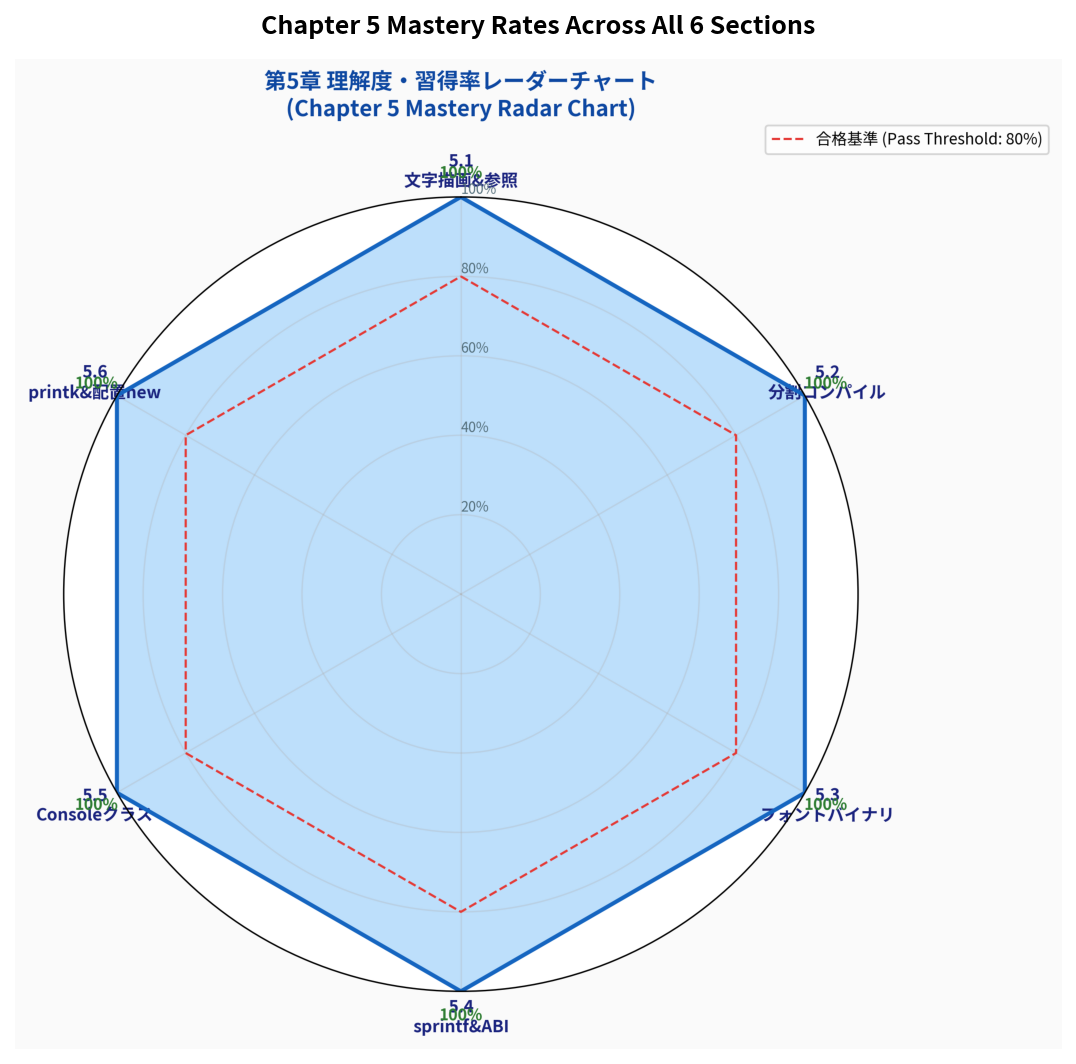

In [11]:
radar_fig_path = Path("result/fig5_ex2_ch5_mastery_radar.png")
plot_chapter5_mastery_radar(radar_fig_path, eval_result["mastery_rates"])

img_radar = Image.open(radar_fig_path)
plt.figure(figsize=(9, 9))
plt.imshow(img_radar)
plt.axis("off")
plt.title("Chapter 5 Mastery Rates Across All 6 Sections", fontsize=12, fontweight="bold", pad=12)
plt.show()


---

## 🏆 まとめと第6章への展望

本章の演習問題を通じて、以下の極めて重要な OS 低レイヤ技術を獲得しました：

1. **文字描画とフォントバイナリのメモリマッピング**:
   - 8x16 ビットマップフォントの MSB ビット展開によるピクセル描画
   - GNU `objcopy` による静的リソースの ELF 埋め込みと 3 大リンカシンボル参照
2. **C++ 言語仕様と分割コンパイル基盤**:
   - 参照（`T&`）による安全なハードウェア・インスタンス抽象化
   - インクルードガードと ODR による堅牢なモジュール分離
3. **標準ライブラリ連携と ABI レベルの可変長引数**:
   - Newlib `sbrk` スタブによる標準 C ライブラリのベアメタル動作
   - System V AMD64 ABI における `va_list` 構造体のレジスタ退避メカニズム
4. **対話型コンソールとカーネルロギング**:
   - 25行×80列文字バッファの行シフトスクロールアルゴリズム
   - `printk()` による書式付きデバッグ出力とバッファ切り詰め安全性
   - 配置 `new` によるカーネルメモリ初期化

### 🚀 次のステップ：第6章「マウス入力とPCI」
第5章までのテキストコンソール画面を飛び出し、GUI の第1歩となる**マウスカーソルの描画**と、マザーボード上のハードウェアデバイス（USB 3.0 xHCI ホストコントローラ）を検出する **PCI バス探索（Configuration Space走査）**、そしてポーリングによるマウス入力制御へと進みます！
